In [1]:
!wget -q -O WELFake_Dataset.csv "https://zenodo.org/records/4561253/files/WELFake_Dataset.csv?download=1"

import os

size_mb = os.path.getsize("WELFake_Dataset.csv") / (1024 ** 2)
print(f"Downloaded WELFake_Dataset.csv ({size_mb:.1f} MB)")

Downloaded WELFake_Dataset.csv (233.7 MB)


In [4]:
import pandas as pd

news_data = pd.read_csv("WELFake_Dataset.csv")

print("Dataset size:", news_data.shape)
print("Columns:", news_data.columns.tolist())
print("\nLabel counts:")
print(news_data["label"].value_counts())

display(news_data.head())

Dataset size: (72134, 4)
Columns: ['Unnamed: 0', 'title', 'text', 'label']

Label counts:
label
1    37106
0    35028
Name: count, dtype: int64


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [5]:
print("Missing values per column:")
print(news_data.isna().sum())

print("\nDuplicate rows:", news_data.duplicated().sum())

Missing values per column:
Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

Duplicate rows: 0


In [6]:
news_data = news_data.drop(columns=["Unnamed: 0"])

news_data["title"] = news_data["title"].fillna("")
news_data["text"] = news_data["text"].fillna("")

news_data["content"] = (
    news_data["title"].str.strip() + " " + news_data["text"].str.strip()
).str.strip()

news_data = news_data[news_data["content"] != ""].copy()

print("Cleaned dataset size:", news_data.shape)
print("Rows with empty content:", (news_data["content"] == "").sum())
display(news_data[["content", "label"]].head(3))

Cleaned dataset size: (72134, 4)
Rows with empty content: 0


,content,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,1
1,Did they post their votes for Hillary already?,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,1


label
Real    37106
Fake    35028
Name: count, dtype: int64


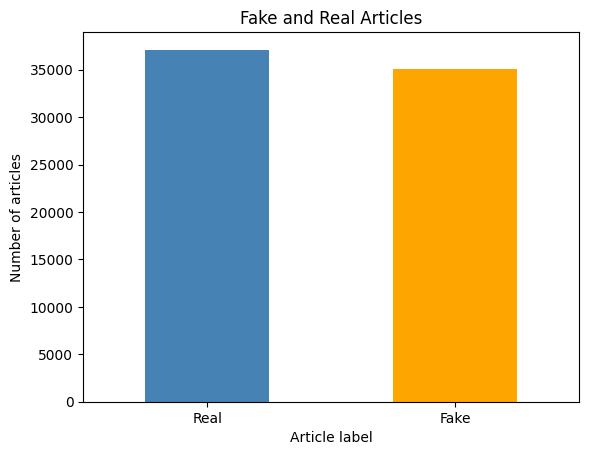

In [7]:
import matplotlib.pyplot as plt

label_counts = news_data["label"].map({0: "Fake", 1: "Real"}).value_counts()

print(label_counts)

label_counts.plot(kind="bar", color=["steelblue", "orange"])
plt.title("Fake and Real Articles")
plt.xlabel("Article label")
plt.ylabel("Number of articles")
plt.xticks(rotation=0)
plt.show()

count    72134.000000
mean       552.724249
std        625.655132
min          1.000000
25%        239.000000
50%        410.000000
75%        679.000000
max      24243.000000
Name: word_count, dtype: float64


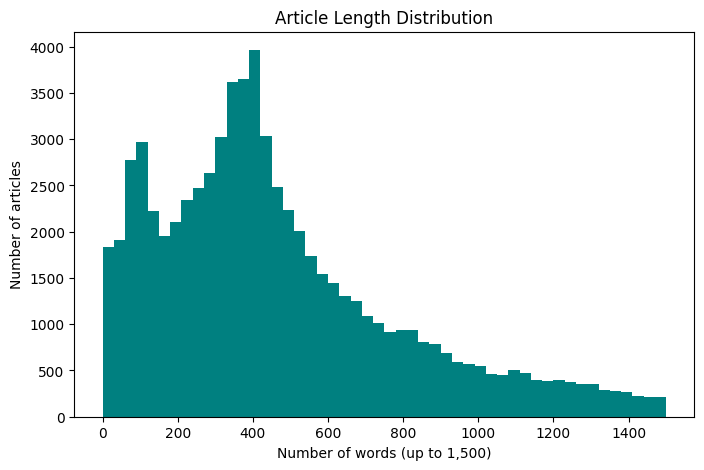

In [8]:
news_data["word_count"] = news_data["content"].str.split().str.len()

print(news_data["word_count"].describe())

plt.figure(figsize=(8, 5))
plt.hist(news_data["word_count"], bins=50, range=(0, 1500), color="teal")
plt.title("Article Length Distribution")
plt.xlabel("Number of words (up to 1,500)")
plt.ylabel("Number of articles")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

X = news_data["content"]
y = news_data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))

Training articles: 57707
Testing articles: 14427


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training text matrix:", X_train_tfidf.shape)
print("Testing text matrix:", X_test_tfidf.shape)
print("Words and phrases learned:", len(vectorizer.get_feature_names_out()))

Training text matrix: (57707, 20000)
Testing text matrix: (14427, 20000)
Words and phrases learned: 20000


In [11]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

lr_model = LogisticRegression(max_iter=1000, solver="liblinear")
lr_model.fit(X_train_tfidf, y_train)

print("Both models finished training.")

Both models finished training.


NAIVE BAYES
              precision    recall  f1-score   support

    Fake (0)      0.879     0.846     0.862      7006
    Real (1)      0.859     0.890     0.874      7421

    accuracy                          0.868     14427
   macro avg      0.869     0.868     0.868     14427
weighted avg      0.869     0.868     0.868     14427

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    Fake (0)      0.958     0.942     0.950      7006
    Real (1)      0.947     0.961     0.954      7421

    accuracy                          0.952     14427
   macro avg      0.952     0.952     0.952     14427
weighted avg      0.952     0.952     0.952     14427



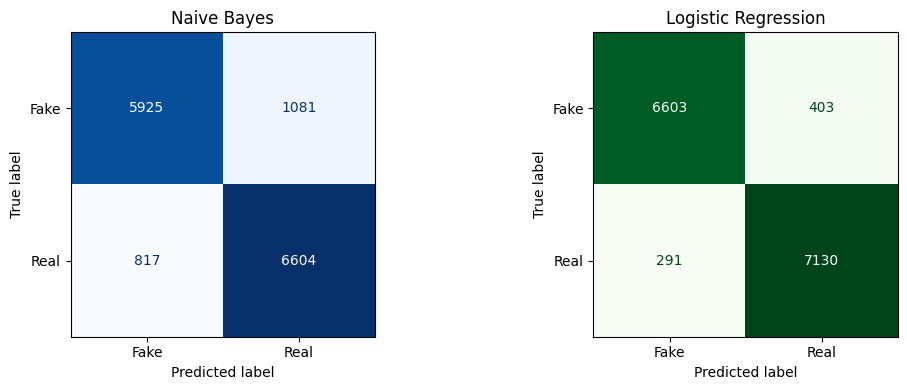

In [12]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

nb_predictions = nb_model.predict(X_test_tfidf)
lr_predictions = lr_model.predict(X_test_tfidf)

print("NAIVE BAYES")
print(classification_report(
    y_test, nb_predictions,
    target_names=["Fake (0)", "Real (1)"],
    digits=3
))

print("LOGISTIC REGRESSION")
print(classification_report(
    y_test, lr_predictions,
    target_names=["Fake (0)", "Real (1)"],
    digits=3
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, nb_predictions,
    display_labels=["Fake", "Real"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Naive Bayes")

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_predictions,
    display_labels=["Fake", "Real"],
    cmap="Greens", ax=axes[1], colorbar=False
)
axes[1].set_title("Logistic Regression")

plt.tight_layout()
plt.show()

In [13]:
import joblib

joblib.dump(lr_model, "fake_news_logistic_model.joblib")
joblib.dump(vectorizer, "tfidf_vectorizer.joblib")

print("Saved model and TF-IDF vectorizer.")

Saved model and TF-IDF vectorizer.


In [14]:
from google.colab import files

files.download("fake_news_logistic_model.joblib")
files.download("tfidf_vectorizer.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
%%writefile app.py
import joblib
import streamlit as st

st.set_page_config(page_title="Fake News Text Classifier", page_icon="📰")

@st.cache_resource
def load_files():
    model = joblib.load("fake_news_logistic_model.joblib")
    vectorizer = joblib.load("tfidf_vectorizer.joblib")
    return model, vectorizer

model, vectorizer = load_files()

st.title("Fake News Text Classifier")
st.write("Paste a news headline or article to see the model's prediction.")

article_text = st.text_area("News text", height=250)

if st.button("Analyze text"):
    if not article_text.strip():
        st.warning("Please paste some text first.")
    else:
        text_numbers = vectorizer.transform([article_text])
        prediction = int(model.predict(text_numbers)[0])

        if prediction == 1:
            st.success("Model prediction: Likely real")
        else:
            st.error("Model prediction: Likely fake")

st.caption(
    "This is a student project. Its prediction is not a fact-check "
    "and should not be used as proof that a news story is true or false."
)

Writing app.py


In [16]:
from google.colab import files
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import sklearn
import numpy
import joblib

print("scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.6.1
NumPy: 2.1.3
joblib: 1.6.0


In [18]:
%%writefile requirements.txt
streamlit>=1.35,<2
scikit-learn==1.6.1
numpy==2.1.3
joblib==1.6.0

Writing requirements.txt


In [19]:
from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
%%writefile README.md
# Fake News Text Classifier

## About this project

For this project, I built a simple app that uses machine learning to look for patterns in news articles and predict whether an article is likely to be fake or real. The app lets someone paste in a headline or article and view the model’s prediction.

## The data

I used the WELFake dataset, which contains 72,134 news articles. Each article has a label: `0` means fake and `1` means real. The dataset is available on [Zenodo](https://zenodo.org/records/4561253).

The article titles and text were combined before training. I kept the dataset CSV out of this project folder because it is large. The download link above can be used to get it again.

## How I built it

First, I checked the data for missing values and duplicates. Then I used TF-IDF to turn the article text into numbers that machine-learning models can work with.

I trained and compared two models using an 80/20 split: most articles were used for training, and the rest were held back to evaluate the models.

- Naive Bayes achieved **86.8% accuracy** on the test data.
- Logistic Regression achieved **95.2% accuracy** on the test data.

I chose Logistic Regression for the app because it performed better on this test set.

## Files in this project

- `app.py` — the app for trying a prediction
- `fake_news_logistic_model.joblib` — the trained model
- `tfidf_vectorizer.joblib` — the tool that converts text into model-ready numbers
- `requirements.txt` — the Python packages needed to run the app
- `Major_Project_Fake_News_Detection.ipynb` — the notebook with the data analysis and model training

## Running the app

Keep `app.py`, both `.joblib` files, and `requirements.txt` together in one folder. On Windows, open a terminal in that folder and run:

    py -m pip install -r requirements.txt
    py -m streamlit run app.py

## A note about the predictions

This project is a learning demonstration, not a fact-checking service. The model can make mistakes, so its prediction should not be treated as proof that an article is true or false.

Overwriting README.md


In [22]:
for label, name in [(0, "FAKE"), (1, "REAL")]:
    positions = [
        i for i, (actual, predicted) in enumerate(
            zip(y_test.to_numpy(), lr_predictions)
        )
        if actual == label
        and predicted == label
        and len(X_test.iloc[i]) <= 1200
    ]

    if positions:
        print(f"\n{name} example from the test data:")
        print(X_test.iloc[positions[0]])


FAKE example from the test data:
California AG pledges to defend birth control insurance coverage SAN FRANCISCO (Reuters) - California Attorney General Xavier Becerra said on Friday he was “prepared to take whatever action it takes” to defend the Obamacare mandate that health insurers provide birth control, now that the Trump administration has moved to circumvent it. The administration’s new contraception exemptions “are another example of the Trump administration trampling on people’s rights, but in this case only women,” Becerra told Reuters.  Becerra and other Democratic attorneys general have filed courtroom challenges to other Trump administration policies involving healthcare, immigration and the environment.

REAL example from the test data:
HERE’S WHAT HILLARY’S “FAIR GROWTH” Economic Plan Means For Americans [Video] If you ve never heard Betsy McCaughey speak   you re in for a treat! She was one of the most outspoken and honest people warning us about Obamacare. She actually

In [23]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, recall_score

svm_model = LinearSVC(C=1.0)
svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

print(f"Linear SVM accuracy: {accuracy_score(y_test, svm_predictions):.3f}")
print(f"Linear SVM macro F1: {f1_score(y_test, svm_predictions, average='macro'):.3f}")
print(f"Fake-news recall: {recall_score(y_test, svm_predictions, pos_label=0):.3f}")

print("\nCurrent Logistic Regression:")
print(f"Accuracy: {accuracy_score(y_test, lr_predictions):.3f}")
print(f"Macro F1: {f1_score(y_test, lr_predictions, average='macro'):.3f}")
print(f"Fake-news recall: {recall_score(y_test, lr_predictions, pos_label=0):.3f}")

Linear SVM accuracy: 0.966
Linear SVM macro F1: 0.966
Fake-news recall: 0.959

Current Logistic Regression:
Accuracy: 0.952
Macro F1: 0.952
Fake-news recall: 0.942


In [24]:
import joblib
from google.colab import files

joblib.dump(svm_model, "fake_news_svm_model.joblib")
print("Saved Linear SVM model.")

files.download("fake_news_svm_model.joblib")

Saved Linear SVM model.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
%%writefile app.py
import joblib
import streamlit as st

st.set_page_config(page_title="Fake News Text Classifier", page_icon="📰")

@st.cache_resource
def load_files():
    model = joblib.load("fake_news_svm_model.joblib")
    vectorizer = joblib.load("tfidf_vectorizer.joblib")
    return model, vectorizer

model, vectorizer = load_files()

st.title("Fake News Text Classifier")
st.write("Paste the full text of a news article for a prediction.")

article_text = st.text_area("News article text", height=250)

if st.button("Analyze text"):
    if not article_text.strip():
        st.warning("Please paste some article text first.")
    else:
        text_numbers = vectorizer.transform([article_text])
        prediction = int(model.predict(text_numbers)[0])

        if prediction == 1:
            st.success("Model prediction: Likely real")
        else:
            st.error("Model prediction: Likely fake")

st.caption(
    "This student project is not a fact-checking service. "
    "Predictions can be wrong and are not proof that a story is true or false."
)

Overwriting app.py


In [26]:
from google.colab import files
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
%%writefile README.md
# Fake News Text Classifier

## What this project does

I built this project to explore whether a computer can learn patterns in news articles and use them to make a fake-or-real prediction. I also made a small Streamlit app so people can try it by pasting in an article.

## The data and how I used it

I used the WELFake dataset from [Zenodo](https://zenodo.org/records/4561253). It contains 72,134 labeled articles: `0` means fake and `1` means real. I joined each article’s title and text, then used TF-IDF to turn the words into numbers the models could work with.

I split the data into training and test sets and compared three models. On the test set, Naive Bayes reached 86.8% accuracy, Logistic Regression reached 95.2%, and Linear SVM reached 96.6%. The Linear SVM also caught 95.9% of the fake articles in that test set, so I chose it for the app.

These scores describe one test on this dataset. They don’t tell us whether a new article is actually true or false.

## Files

- `app.py` is the app people can use.
- `fake_news_svm_model.joblib` is the trained SVM model.
- `tfidf_vectorizer.joblib` prepares text for the model.
- `requirements.txt` lists the packages needed to run the app.
- `Major_Project_Fake_News_Detection.ipynb` contains my analysis and training steps.

The dataset CSV isn’t included because it is large. It can be downloaded from the Zenodo link above if the model needs to be retrained.

## Running the app

Keep `app.py`, both `.joblib` files, and `requirements.txt` in the same folder. In a Windows terminal opened in that folder, run:

    py -m pip install -r requirements.txt
    py -m streamlit run app.py

## One important limitation

This is a student project, not a fact-checking service. The model can make mistakes, especially on short text or articles that are unlike the examples it learned from. Its prediction should not be treated as proof that a story is true or false.

Overwriting README.md


In [28]:
from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>